<a href="https://colab.research.google.com/github/tien10022001/h-c-m-y/blob/main/ITA202_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 3: HỒI QUY TUYẾN TÍNH (LINEAR REGRESSION)
- **Môn học:** Học máy cơ bản (ITA202)
- **Sinh viên thực hiện:** Trương Công Tiến
- **Mã sinh viên:** PH68945

---
### Mục tiêu bài Lab:
1. Hiểu bài toán Hồi quy (Regression) và cách áp dụng mô hình Tuyến tính.
2. Huấn luyện mô hình Hồi quy tuyến tính trên tập dữ liệu thực tế.
3. Đánh giá chất lượng mô hình bằng các chỉ số: MAE (Mean Absolute Error), MSE (Mean Squared Error), R² (R-squared Score).
4. Trực quan hóa kết quả dự đoán của mô hình.

## Bài 1: Xây dựng mô hình Hồi quy tuyến tính
**Yêu cầu:**
- Tạo dữ liệu giả lập có mối quan hệ tuyến tính giữa biến X và y (ví dụ: $y = 2X + 1 + \text{nhiễu}$).
- Sử dụng thư viện `sklearn.linear_model.LinearRegression` để huấn luyện mô hình.
- In ra các hệ số của mô hình (`coefficient` và `intercept`).

In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Tạo dữ liệu giả lập có mối quan hệ tuyến tính: y = 2*X + 1 + nhiễu
np.random.seed(42)  # Cố định seed ngẫu nhiên
X_sim = 2 * np.random.rand(100, 1)                      # 100 điểm dữ liệu trong khoảng [0, 2]
noise = np.random.randn(100, 1) * 0.5                  # Nhiễu Gauss có độ lệch chuẩn 0.5
y_sim = 2 * X_sim + 1 + noise                          # Công thức lý thuyết y = 2*X + 1

print(f"Kích thước tập X: {X_sim.shape}")
print(f"Kích thước tập y: {y_sim.shape}")

# 2. Khởi tạo và huấn luyện mô hình Linear Regression
reg_sim = LinearRegression()
reg_sim.fit(X_sim, y_sim)

# 3. In ra các hệ số hồi quy ước lượng được
slope = reg_sim.coef_[0][0]
intercept = reg_sim.intercept_[0]

print("\n--- KẾT QUẢ ƯỚC LƯỢNG HỆ SỐ MÔ HÌNH ---")
print(f"Hệ số góc (Slope / Coefficient w1): {slope:.4f} (Lý thuyết: 2)")
print(f"Hệ số chặn (Intercept / Bias w0):    {intercept:.4f} (Lý thuyết: 1)")
print(f"Phương trình hồi quy tìm được: y = {slope:.4f} * X + {intercept:.4f}")

Kích thước tập X: (100, 1)
Kích thước tập y: (100, 1)

--- KẾT QUẢ ƯỚC LƯỢNG HỆ SỐ MÔ HÌNH ---
Hệ số góc (Slope / Coefficient w1): 1.8851 (Lý thuyết: 2)
Hệ số chặn (Intercept / Bias w0):    1.1075 (Lý thuyết: 1)
Phương trình hồi quy tìm được: y = 1.8851 * X + 1.1075


## Bài 2: Đánh giá mô hình
**Yêu cầu:**
- Sử dụng tập dữ liệu `diabetes` từ `sklearn.datasets` (chỉ lấy 1 đặc trưng duy nhất để dễ trực quan hóa: chỉ số BMI).
- Chia dữ liệu Train/Test (80% Train, 20% Test).
- Huấn luyện mô hình và tính toán các chỉ số đánh giá: **MAE**, **MSE**, **RMSE**, **R-squared ($R^2$)** trên tập Test.
- **Giải thích ý nghĩa của các chỉ số này thông qua comment**.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Nạp tập dữ liệu diabetes và chọn 1 đặc trưng BMI (index 2)
diabetes = load_diabetes()
X_diabetes = diabetes.data[:, np.newaxis, 2]  # Lấy cột index 2 (BMI)
y_diabetes = diabetes.target                  # Tiến triển bệnh đái tháo đường

# 2. Chia tập dữ liệu Train (80%) và Test (20%)
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_diabetes, y_diabetes, test_size=0.2, random_state=42
)

# 3. Huấn luyện mô hình Linear Regression
model_diabetes = LinearRegression()
model_diabetes.fit(X_train_d, y_train_d)
y_pred_d = model_diabetes.predict(X_test_d)

# 4. Tính toán các chỉ số đánh giá
mae_d = mean_absolute_error(y_test_d, y_pred_d)
mse_d = mean_squared_error(y_test_d, y_pred_d)
rmse_d = np.sqrt(mse_d)
r2_d = r2_score(y_test_d, y_pred_d)

print("--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ---")
print(f"Hệ số góc w1: {model_diabetes.coef_[0]:.4f}")
print(f"Hệ số chặn w0: {model_diabetes.intercept_:.4f}")
print(f"MAE  (Mean Absolute Error):     {mae_d:.4f}")
print(f"MSE  (Mean Squared Error):      {mse_d:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse_d:.4f}")
print(f"R²   (R-squared Score):         {r2_d:.4f}")

# =========================================================================
# GIẢI THÍCH CHI TIẾT Ý NGHĨA CÁC CHỈ SỐ:
# 1. MAE (Mean Absolute Error - Sai số tuyệt đối trung bình):
#    - Đo khoảng cách tuyệt đối trung bình giữa giá trị dự đoán và thực tế.
#    - Cùng đơn vị đo với biến mục tiêu y, ít bị ảnh hưởng bởi giá trị ngoại lệ (outliers).
#    - MAE = 52.26 nghĩa là trung bình mỗi ca bệnh dự đoán chênh lệch khoảng 52.26 điểm.
#
# 2. MSE (Mean Squared Error - Sai số bình phương trung bình):
#    - Bình phương độ lệch trước khi lấy trung bình: MSE = sum((y_true - y_pred)^2)/n.
#    - Phạt rất nặng các điểm sai số lớn. MSE càng gần 0 thì mô hình càng tốt.
#
# 3. RMSE (Root Mean Squared Error):
#    - Căn bậc hai của MSE, đưa sai số về lại cùng thứ nguyên (đơn vị gốc) với y.
#
# 4. R-squared (R² - Hệ số xác định):
#    - Đo lường tỷ lệ phần trăm phương sai của y được giải thích bởi mô hình (R² = 1 - SS_res/SS_tot).
#    - R² = 0.2334 có nghĩa là chỉ với 1 biến BMI đơn lẻ đã giải thích được 23.34% sự biến thiên của bệnh tiểu đường.
# =========================================================================

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ---
Hệ số góc w1: 998.5777
Hệ số chặn w0: 152.0034
MAE  (Mean Absolute Error):     52.2600
MSE  (Mean Squared Error):      4061.8259
RMSE (Root Mean Squared Error): 63.7325
R²   (R-squared Score):         0.2334


## Bài 3: Trực quan hóa kết quả
**Yêu cầu:**
- Sử dụng thư viện `matplotlib` để vẽ biểu đồ tán xạ (*scatter plot*) của dữ liệu thực tế.
- Vẽ đường thẳng hồi quy (đường dự đoán) của mô hình lên cùng một biểu đồ để so sánh.

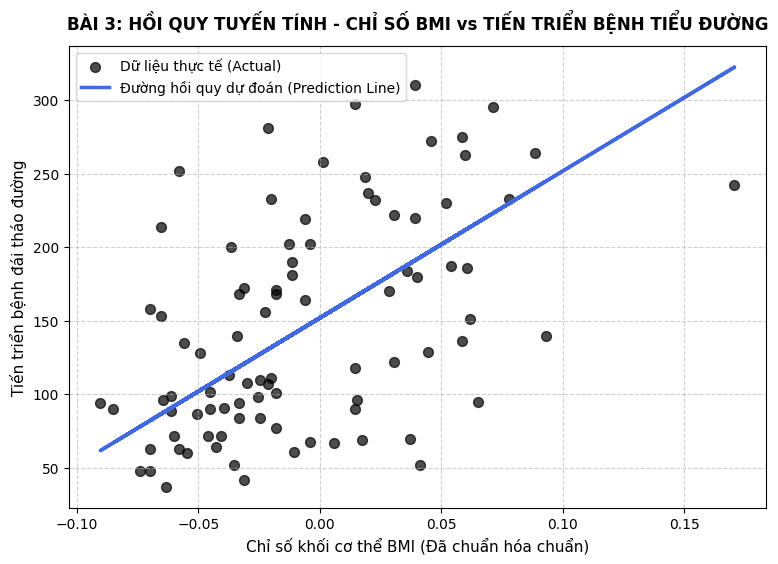

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# 1. Vẽ biểu đồ tán xạ dữ liệu thực tế
plt.scatter(X_test_d, y_test_d, color="black", alpha=0.7, edgecolors="k", s=50, label="Dữ liệu thực tế (Actual)")

# 2. Vẽ đường thẳng hồi quy dự đoán
plt.plot(X_test_d, y_pred_d, color="royalblue", linewidth=2.5, label="Đường hồi quy dự đoán (Prediction Line)")

# Trang trí biểu đồ
plt.title("BÀI 3: HỒI QUY TUYẾN TÍNH - CHỈ SỐ BMI vs TIẾN TRIỂN BỆNH TIỂU ĐƯỜNG", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Chỉ số khối cơ thể BMI (Đã chuẩn hóa chuẩn)", fontsize=11)
plt.ylabel("Tiến triển bệnh đái tháo đường", fontsize=11)
plt.legend(loc="upper left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Bài 4: Quy trình ML hoàn chỉnh - Thử nghiệm mô hình Regression trên California Housing
**Yêu cầu:**
- Áp dụng Hồi quy tuyến tính vào bài toán dự đoán giá nhà sử dụng tập dữ liệu `california_housing`.
- Thực hiện đầy đủ 5 bước của quy trình Machine Learning:
  1. **Load Data**: Nạp dữ liệu.
  2. **Preprocess (Scaling)**: Chia tập train/test và chuẩn hóa đặc trưng bằng `StandardScaler`.
  3. **Train**: Huấn luyện mô hình hồi quy đa biến.
  4. **Evaluate**: Tính toán các chỉ số đánh giá (MSE, RMSE, MAE, R²).
  5. **Visualize**: Trực quan hóa kết quả dự đoán (Actual vs Predicted & Phân phối phần dư).

Số lượng quan sát: 20640 dòng, 8 đặc trưng
Danh sách các thuộc tính: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

--- TRỌNG SỐ CÁC ĐẶC TRƯNG SAU CHUẨN HÓA ---
 Đặc trưng  Hệ số hồi quy
    MedInc       0.854383
 AveBedrms       0.339259
  HouseAge       0.122546
Population      -0.002308
  AveOccup      -0.040829
  AveRooms      -0.294410
 Longitude      -0.869842
  Latitude      -0.896929
Hệ số chặn (Bias): 2.0719

--- KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST CALIFORNIA HOUSING ---
MSE  (Mean Squared Error):      0.5559
RMSE (Root Mean Squared Error): 0.7456 (~ 74558.14 USD)
MAE  (Mean Absolute Error):     0.5332 (~ 53320.01 USD)
R²   (Hệ số xác định):          0.5758 (57.58% phương sai được giải thích)


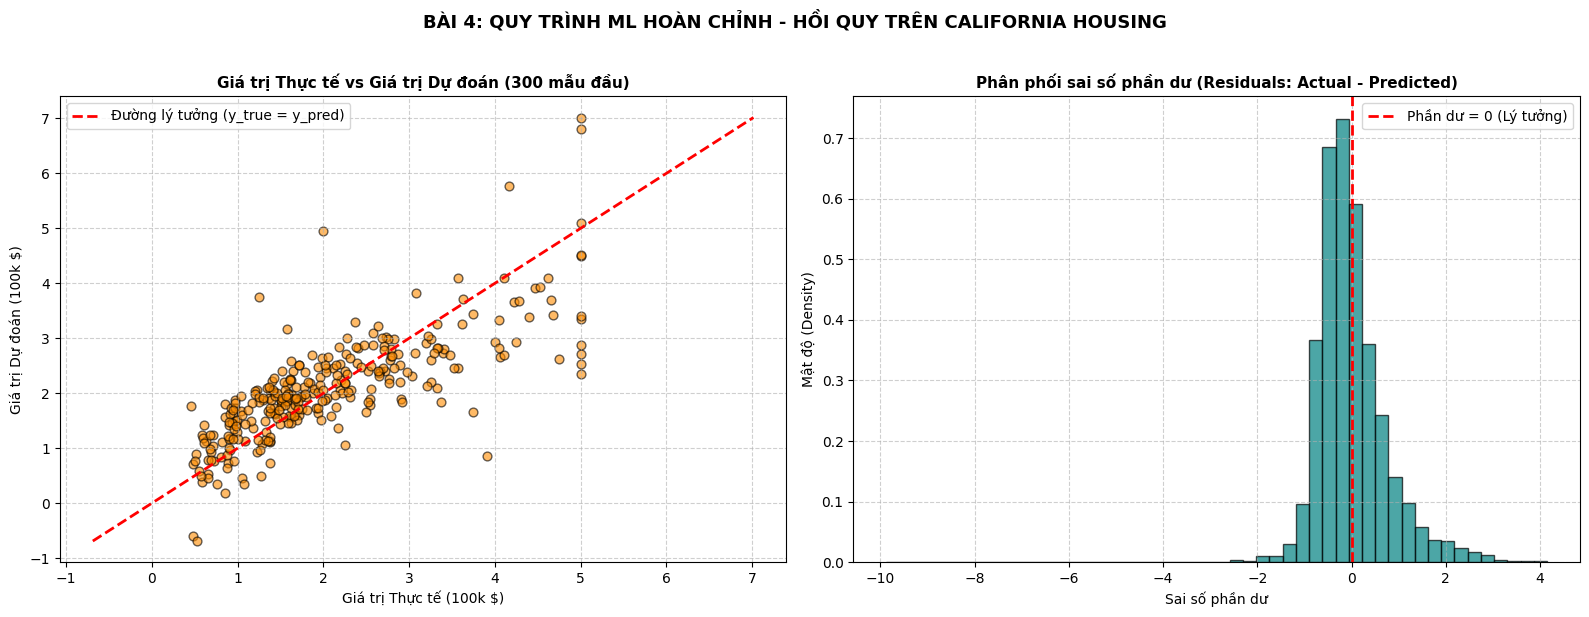

In [4]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler

# BƯỚC 1: LOAD DỮ LIỆU
housing = fetch_california_housing(as_frame=True)
X_h = housing.data
y_h = housing.target  # Đơn vị: 100,000 USD

print(f"Số lượng quan sát: {X_h.shape[0]} dòng, {X_h.shape[1]} đặc trưng")
print(f"Danh sách các thuộc tính: {list(X_h.columns)}")

# BƯỚC 2: CHIA TẬP TRAIN/TEST VÀ CHUẨN HÓA DỮ LIỆU (SCALING)
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_h, y_h, test_size=0.2, random_state=42
)

scaler = StandardScaler()
# fit_transform trên tập Train, chỉ transform trên tập Test chống Data Leakage
X_train_h_scaled = scaler.fit_transform(X_train_h)
X_test_h_scaled = scaler.transform(X_test_h)

# BƯỚC 3: HUẤN LUYỆN MÔ HÌNH HỒI QUY ĐA BIẾN
model_housing = LinearRegression()
model_housing.fit(X_train_h_scaled, y_train_h)

coeff_df = pd.DataFrame({
    "Đặc trưng": X_h.columns,
    "Hệ số hồi quy": model_housing.coef_
}).sort_values(by="Hệ số hồi quy", ascending=False)
print("\n--- TRỌNG SỐ CÁC ĐẶC TRƯNG SAU CHUẨN HÓA ---")
print(coeff_df.to_string(index=False))
print(f"Hệ số chặn (Bias): {model_housing.intercept_:.4f}")

# BƯỚC 4: ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST
y_pred_h = model_housing.predict(X_test_h_scaled)
mse_h = mean_squared_error(y_test_h, y_pred_h)
rmse_h = np.sqrt(mse_h)
mae_h = mean_absolute_error(y_test_h, y_pred_h)
r2_h = r2_score(y_test_h, y_pred_h)

print("\n--- KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST CALIFORNIA HOUSING ---")
print(f"MSE  (Mean Squared Error):      {mse_h:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse_h:.4f} (~ {rmse_h*100000:.2f} USD)")
print(f"MAE  (Mean Absolute Error):     {mae_h:.4f} (~ {mae_h*100000:.2f} USD)")
print(f"R²   (Hệ số xác định):          {r2_h:.4f} ({r2_h*100:.2f}% phương sai được giải thích)")

# BƯỚC 5: TRỰC QUAN HÓA KẾT QUẢ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Actual vs Predicted cho 300 mẫu
axes[0].scatter(y_test_h.iloc[:300], y_pred_h[:300], color="darkorange", alpha=0.6, edgecolors="k", s=40)
min_v = min(y_test_h.iloc[:300].min(), y_pred_h[:300].min())
max_v = max(y_test_h.iloc[:300].max(), y_pred_h[:300].max())
axes[0].plot([min_v, max_v], [min_v, max_v], "r--", linewidth=2, label="Đường lý tưởng (y_true = y_pred)")
axes[0].set_title("Giá trị Thực tế vs Giá trị Dự đoán (300 mẫu đầu)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Giá trị Thực tế (100k $)", fontsize=10)
axes[0].set_ylabel("Giá trị Dự đoán (100k $)", fontsize=10)
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Phân phối sai số phần dư (Residuals)
residuals = y_test_h - y_pred_h
axes[1].hist(residuals, bins=50, color="teal", edgecolor="black", alpha=0.7, density=True)
axes[1].axvline(0, color="red", linestyle="--", linewidth=2, label="Phần dư = 0 (Lý tưởng)")
axes[1].set_title("Phân phối sai số phần dư (Residuals: Actual - Predicted)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Sai số phần dư", fontsize=10)
axes[1].set_ylabel("Mật độ (Density)", fontsize=10)
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("BÀI 4: QUY TRÌNH ML HOÀN CHỈNH - HỒI QUY TRÊN CALIFORNIA HOUSING", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()